# 3 · Vector and hybrid search: matching by meaning

**The question:** keyword search needs the same words. Does matching by *meaning* do better, and does
blending both beat either one?

**How vectors work:** a language model (here *bge-large*) turns each text into 1,024 numbers so that
texts with similar meaning get similar numbers. Search = find the abstracts whose numbers are closest
to the question's. This is the search step behind AI assistants that "chat with your documents" (RAG).

**The test:** the same SciFact questions and expert labels as lesson 1. The abstract vectors were
computed in the rag-bedrock-compare project; this lesson reuses them.

In [1]:
%matplotlib inline
import os, json
os.chdir('..')  # run from the project root so data/ and results/ resolve
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from oslab import plot, stack
plot.style()
pd.set_option('display.width', 160)
assert stack.is_up(), 'start the stack first: docker compose up -d'

from oslab import hybrid, search, beir, metrics, tune

## 1 · First check the plumbing: approximate vs exact

Comparing a question against every abstract is exact but slow at millions of documents. Search
engines use **HNSW**, a graph that jumps quickly toward the closest vectors, accepting that it may
occasionally miss one. Known answer: brute force in numpy. How many of the exact top 10 does each
index find?

In [2]:
_, q, rel = beir.load('data/beir/scifact', 'test')
{b: hybrid.ann_recall(b, q) for b in ('os-vector', 'pg-vector')}

{'os-vector': 1.0, 'pg-vector': 1.0}

Both find exactly the same top 10 (1.0). At 5,000 abstracts that's expected; at millions, the
HNSW settings (`m`, `ef_search`) trade speed for this number, and it's worth re-measuring.

The *exact* vector run reproduces rag-bedrock-compare's 0.744 nDCG@10 (here 0.746: the question
vectors were computed on CPU instead of GPU, a tiny numeric difference).

## 2 · Hybrid: blending keyword and meaning scores

OpenSearch can run BM25 and vector search in one query, then blend. The two scores are on different
scales, so a *search pipeline* first rescales each list to 0-1 (*min-max*), then takes a weighted
average. The weight was picked on the train questions only:

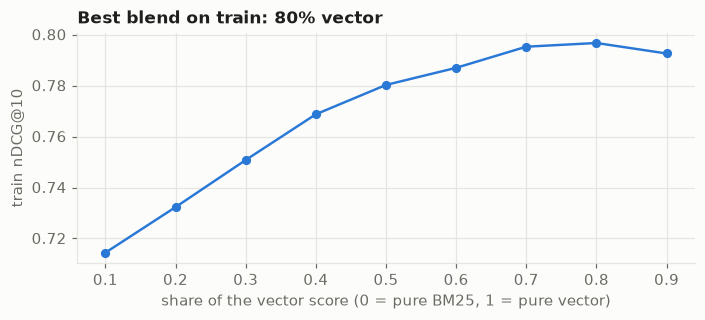

In [3]:
hb = json.load(open('results/hybrid-best.json'))
w = pd.Series(hb['train_ndcg@10']); w.index = w.index.astype(float)
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.plot(w.index, w.values, marker='o', markersize=5, color=plot.SERIES[0])
ax.set_xlabel('share of the vector score (0 = pure BM25, 1 = pure vector)'); ax.set_ylabel('train nDCG@10')
ax.set_title(f"Best blend on train: {hb['vector_weight']:.0%} vector")
plt.tight_layout()

The other option, **reciprocal rank fusion (RRF)**, ignores scores and blends by *rank* (1st, 2nd, ...),
so there's no weight to tune.

## 3 · The test result

In [4]:
names = ['os-bm25', 'os-bm25-tuned', 'os-vector', 'pg-vector', 'os-hybrid', 'os-hybrid-rrf']
t = pd.DataFrame([json.load(open(f'results/scifact-{b}.json')) for b in names])
t[['backend', 'ndcg@10', 'recall@10', 'mrr@10', 'p50_ms']].round(3).sort_values('ndcg@10', ascending=False)

,backend,ndcg@10,recall@10,mrr@10,p50_ms
4,os-hybrid,0.752,0.877,0.721,25.502
5,os-hybrid-rrf,0.750,0.872,0.719,25.846
3,pg-vector,0.746,0.873,0.712,20.079
2,os-vector,0.746,0.873,0.712,2.784
1,os-bm25-tuned,0.690,0.820,0.657,1.140
0,os-bm25,0.610,0.750,0.572,1.252


In [5]:
cmp = json.load(open('results/hybrid-compare.json'))
for k in ('vector_vs_bm25', 'hybrid_vs_vector', 'rrf_vs_vector', 'hybrid_vs_bm25'):
    d = cmp[k]; print(f"{k:17s} gain {d['mean_diff']:+.3f}   95% interval [{d['ci95'][0]:+.3f}, {d['ci95'][1]:+.3f}]")

vector_vs_bm25    gain +0.057   95% interval [+0.023, +0.090]
hybrid_vs_vector  gain +0.006   95% interval [-0.006, +0.018]
rrf_vs_vector     gain +0.004   95% interval [-0.022, +0.030]
hybrid_vs_bm25    gain +0.063   95% interval [+0.032, +0.092]


**Reading it:**
- **Meaning beats keywords** here: vector search is +0.057 over even the *tuned* BM25.
- **Hybrid adds almost nothing on top** (+0.006, and the interval includes zero). Many articles claim
  hybrid always wins; on this data the evidence doesn't support it. It tends to help more when
  questions contain exact codes, names or rare terms that embedding models blur.
- OpenSearch's vector index and pgvector return identical results. The difference is operational:
  pgvector keeps vectors next to the rows they describe; OpenSearch adds BM25, hybrid pipelines and
  scale-out in the same engine.

## 4 · Where keyword and meaning disagree

In [6]:
corpus, _, _ = beir.load('data/beir/scifact', 'test')
bm, vec = search.retriever('os-bm25-tuned'), search.retriever('exact-vector')
diff = []
for qid, text in q.items():
    gold = set(rel[qid])
    b_hit, v_hit = bool(gold & set(bm(text, 10))), bool(gold & set(vec(text, 10)))
    if v_hit and not b_hit:
        diff.append((qid, text))
print(len(diff), 'questions where only vector search found a right abstract; first two:')
for qid, text in diff[:2]:
    gid = next(iter(rel[qid]))
    print('\nQ:', text); print('A:', corpus[gid]['title'])

24 questions where only vector search found a right abstract; first two:

Q: DMRT1 is a sex-determining gene that is epigenetically regulated by the MHM region.
A: Somatic sex identity is cell-autonomous in the chicken

Q: Epidemiological disease burden from noncommunicable diseases is more prevalent in low economic settings.
A: Global, regional, and national comparative risk assessment of 79 behavioural, environmental and occupational, and metabolic risks or clusters of risks, 1990–2015: a systematic analysis for the Global Burden of Disease Study 2015


These are typically paraphrases: the right abstract says the same thing in different words, which
BM25 can't see.

## When *not* to use OpenSearch for this

- **Already on Postgres, under a few million vectors:** pgvector gave identical results here, with no
  second system to keep in sync.
- **Serverless and pay-per-query:** Amazon S3 Vectors (see rag-bedrock-compare) has no idle cost.
  Avoid OpenSearch *Serverless* for small projects: its minimum charge is several hundred dollars a month.

**Industry uses:** retrieval for AI assistants (RAG), "more like this" recommendations, semantic
product search, duplicate and near-duplicate detection.